<a href="https://colab.research.google.com/github/Sakshit16/practical9/blob/main/EE518_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [4]:
FILE_PATH = "Plant_1_Generation_Data.csv.zip"
OUT_DIR = "solar_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_csv(FILE_PATH)

In [5]:
# DATE_TIME format dd-mm-YYYY HH:MM hai, isliye dayfirst zaroori hai
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")
df["DATE"] = df["DATE_TIME"].dt.date
df["HOUR"] = df["DATE_TIME"].dt.hour
df["TIME"] = df["DATE_TIME"].dt.time
print("Shape:", df.shape)
print("\nColumns / dtypes:\n", df.dtypes)
print("\nDate range:", df["DATE_TIME"].min(), "->", df["DATE_TIME"].max())
print("Inverters:", df["SOURCE_KEY"].nunique())
print("\nMissing values:\n", df.isna().sum())
print("\nSummary:\n", df.describe())

Shape: (68778, 10)

Columns / dtypes:
 DATE_TIME      datetime64[ns]
PLANT_ID                int64
SOURCE_KEY             object
DC_POWER              float64
AC_POWER              float64
DAILY_YIELD           float64
TOTAL_YIELD           float64
DATE                   object
HOUR                    int32
TIME                   object
dtype: object

Date range: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00
Inverters: 22

Missing values:
 DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
DATE           0
HOUR           0
TIME           0
dtype: int64

Summary:
                            DATE_TIME   PLANT_ID      DC_POWER      AC_POWER  \
count                          68778    68778.0  68778.000000  68778.000000   
mean   2020-06-01 08:02:49.458256896  4135001.0   3147.426211    307.802752   
min              2020-05-15 00:00:00  4135001.0      0.000000      0.000000   
25%              2020-05-24 00:45:00  4135001.0  

In [9]:
# 2. DATA CLEANING / CHECKS
# -----------------------------------------------------------------
print("\nDuplicates:", df.duplicated(["DATE_TIME", "SOURCE_KEY"]).sum())
# Expected 15-min readings: 34 din x 96 x 22 inverters = 71,808, actual kam hai
# => kuch readings missing hain (inverter/communication down)
expected = df["DATE"].nunique() * 96 * df["SOURCE_KEY"].nunique()
print(f"Expected rows: {expected}, Actual rows: {len(df)}, Missing: {expected -
len(df)}")


Duplicates: 0
Expected rows: 71808, Actual rows: 68778, Missing: 3030


In [8]:
# -----------------------------------------------------------------
# 3. PLANT LEVEL AGGREGATION (har timestamp par saare inverters ka total)
# -----------------------------------------------------------------
plant = (df.groupby("DATE_TIME")[["DC_POWER", "AC_POWER"]].sum().reset_index())
plant["DATE"] = plant["DATE_TIME"].dt.date
plant["HOUR"] = plant["DATE_TIME"].dt.hour
# Daily yield: har inverter ka din ka max DAILY_YIELD, phir sab inverters ka sum
daily_inv = df.groupby(["DATE", "SOURCE_KEY"])["DAILY_YIELD"].max().reset_index()
daily_plant = daily_inv.groupby("DATE")["DAILY_YIELD"].sum()
print("\nBest 5 days (total kWh):\n", daily_plant.nlargest(5))
print("\nWorst 5 days (total kWh):\n", daily_plant.nsmallest(5))


Best 5 days (total kWh):
 DATE
2020-05-20    193770.0
2020-05-25    192862.0
2020-05-23    186728.0
2020-06-13    185308.0
2020-05-28    183432.0
Name: DAILY_YIELD, dtype: float64

Worst 5 days (total kWh):
 DATE
2020-05-18    117738.0
2020-06-11    123626.0
2020-06-01    127458.0
2020-06-12    127815.0
2020-06-17    129571.0
Name: DAILY_YIELD, dtype: float64


In [10]:
# 4. INVERTER PERFORMANCE
inv_perf = (df.groupby("SOURCE_KEY")
              .agg(avg_dc=("DC_POWER", "mean"),
                   avg_ac=("AC_POWER", "mean"),
                   max_ac=("AC_POWER", "max"))
              .sort_values("avg_ac", ascending=False))
# Daytime efficiency (AC/DC), jab DC > 0 ho
day = df[df["DC_POWER"] > 0].copy()
day["EFFICIENCY"] = day["AC_POWER"] / day["DC_POWER"] * 100
inv_perf["efficiency_%"] = day.groupby("SOURCE_KEY")["EFFICIENCY"].mean()
# Daily yield per inverter (average over days)
inv_perf["avg_daily_yield"] = daily_inv.groupby("SOURCE_KEY")["DAILY_YIELD"].mean()
print("\nInverter performance:\n", inv_perf.round(2))
# Underperforming inverters (plant average se 5% neeche)
threshold = inv_perf["avg_daily_yield"].mean() * 0.95
under = inv_perf[inv_perf["avg_daily_yield"] < threshold]
print("\nUnderperforming inverters (<95% of avg):\n", under.round(2))
# NOTE: Is dataset me AC ~ DC ka 10% aata hai (efficiency ~9.8%). Ye real
# efficiency nahi hai - DC_POWER column ka unit/scaling issue hai (known issue).
# Isliye relative comparison karo, absolute efficiency nahi.


Inverter performance:
                   avg_dc  avg_ac   max_ac  efficiency_%  avg_daily_yield
SOURCE_KEY                                                              
adLQvlD726eNBSB  3269.57  319.69  1405.59          9.77          7443.84
1IF53ai7Xc0U56Y  3226.34  315.49  1394.51          9.77          7348.81
3PZuoBAID5Wc2HD  3221.02  314.97  1399.22          9.77          7341.28
McdE0feGgRqW7Ca  3211.31  314.05  1405.80          9.77          7341.78
VHMLBKoKgIrUVDU  3210.10  313.90  1394.21          9.77          7347.00
iCRJl6heRkivqQ3  3196.07  312.54  1407.54          9.77          7301.99
uHbuxQJl8lW7ozc  3195.32  312.47  1377.25          9.77          7303.45
ZnxXDlPa8U1GXgE  3194.06  312.35  1391.64          9.77          7310.44
zVJPv84UY57bAof  3187.24  311.68  1397.09          9.77          7268.21
YxYtjZvoooNbGkE  3179.49  310.93  1410.53          9.77          7219.85
wCURE6d3bPkepu2  3170.70  310.06  1410.95          9.77          7235.29
pkci93gMrogZuBj  3166.60  3

In [15]:
# 5. PLOTS
plt.style.use("seaborn-v0_8-whitegrid")

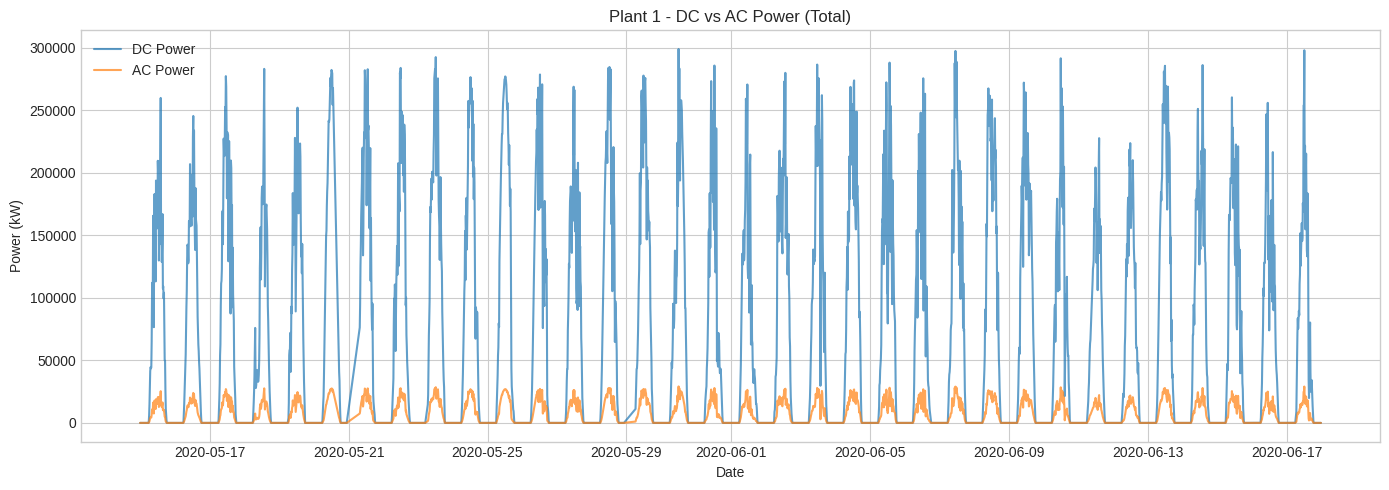

In [14]:
# 5a. Plant DC vs AC over time
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(plant["DATE_TIME"], plant["DC_POWER"], label="DC Power", alpha=0.7)
ax.plot(plant["DATE_TIME"], plant["AC_POWER"], label="AC Power", alpha=0.7)
ax.set(title="Plant 1 - DC vs AC Power (Total)", xlabel="Date", ylabel="Power (kW)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/01_dc_ac_power.png", dpi=150)

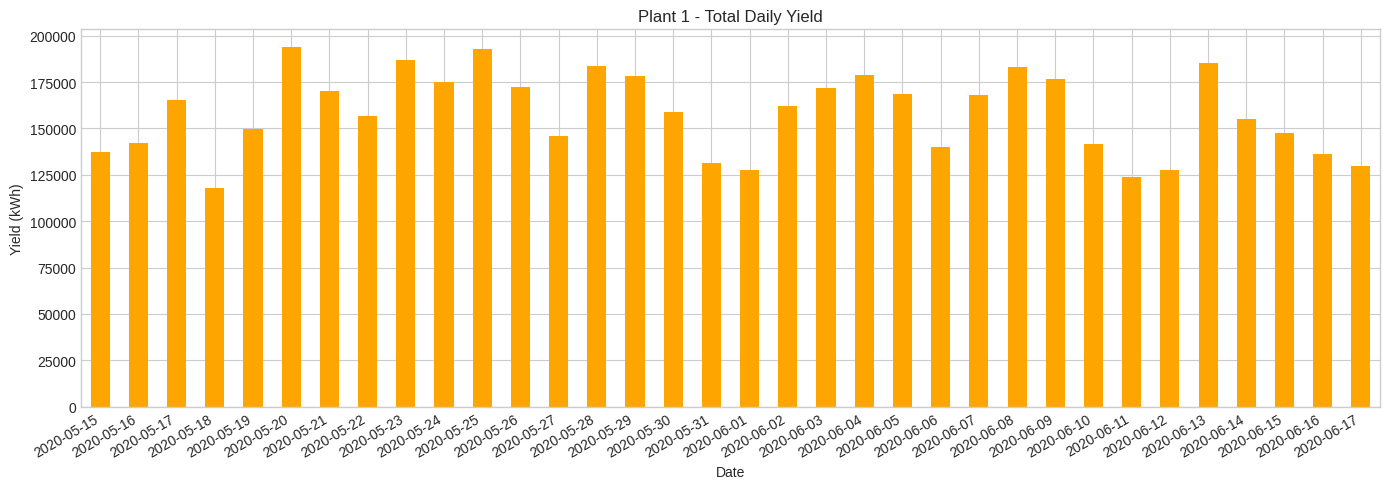

In [16]:
# 5b. Daily yield
fig, ax = plt.subplots(figsize=(14, 5))
daily_plant.plot(kind="bar", ax=ax, color="orange")
ax.set(title="Plant 1 - Total Daily Yield", xlabel="Date", ylabel="Yield (kWh)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/02_daily_yield.png", dpi=150)

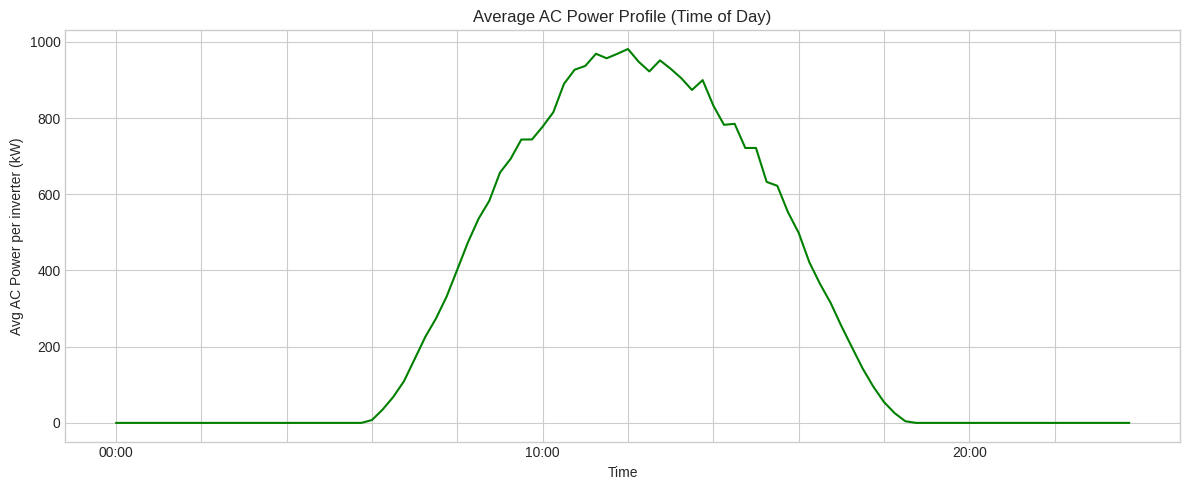

In [18]:
# 5c. Average daily power profile (din ke ghante ke hisaab se)
profile = df.groupby(df["DATE_TIME"].dt.strftime("%H:%M"))["AC_POWER"].mean()
fig, ax = plt.subplots(figsize=(12, 5))
profile.plot(ax=ax, color="green")
ax.set(title="Average AC Power Profile (Time of Day)", xlabel="Time", ylabel="Avg AC Power per inverter (kW)")
ax.set_xticks(range(0, 96, 8))
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/03_daily_profile.png", dpi=150)

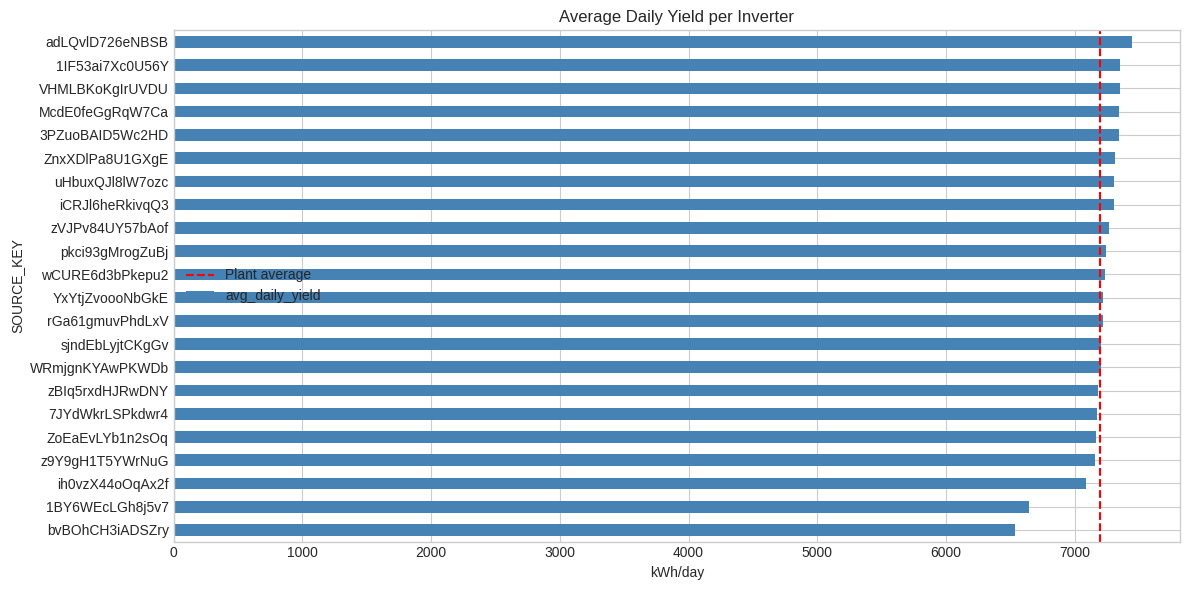

In [20]:
# 5d. Inverter comparison
fig, ax = plt.subplots(figsize=(12, 6))
inv_perf["avg_daily_yield"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(inv_perf["avg_daily_yield"].mean(), color="red", ls="--", label="Plant average")
ax.set(title="Average Daily Yield per Inverter", xlabel="kWh/day")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/04_inverter_comparison.png", dpi=150)

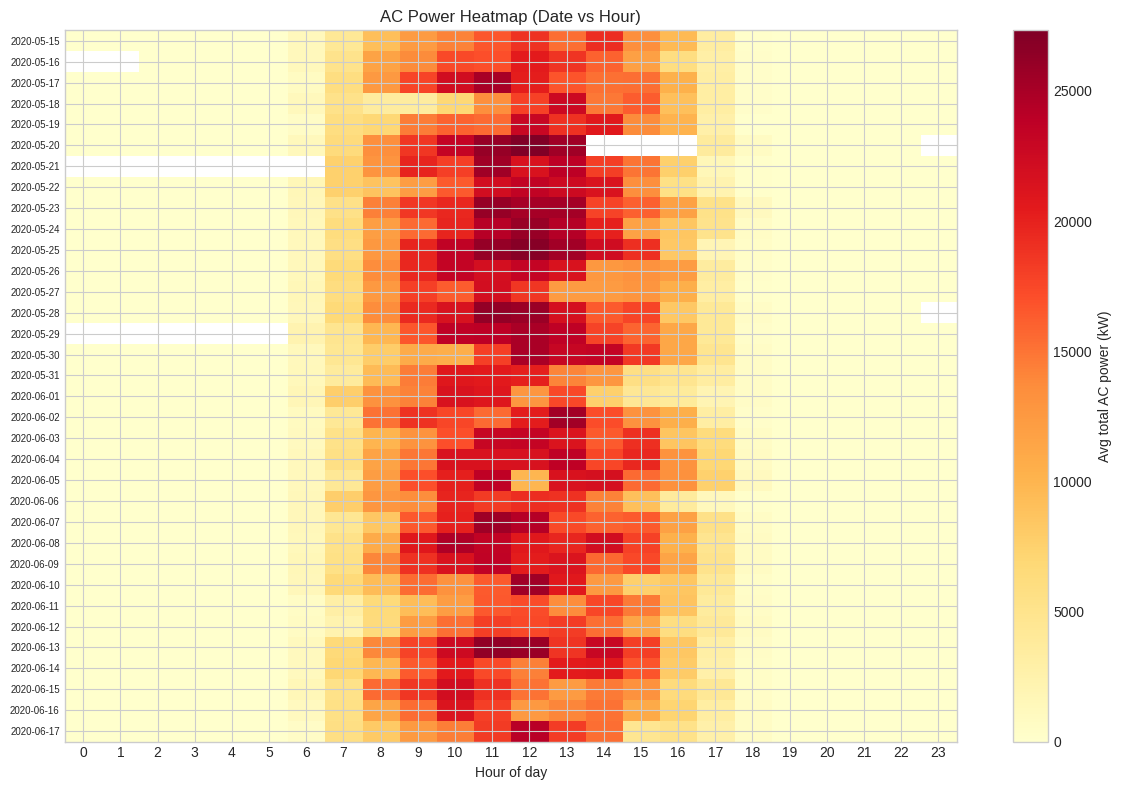

In [21]:
# 5e. Heatmap: din vs ghanta (AC power)
heat = plant.pivot_table(index="DATE", columns="HOUR", values="AC_POWER",
aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 8))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index, fontsize=7)
ax.set(title="AC Power Heatmap (Date vs Hour)", xlabel="Hour of day")
fig.colorbar(im, label="Avg total AC power (kW)")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/05_heatmap.png", dpi=150)

In [22]:
# 5f. DC vs AC scatter (conversion check)
fig, ax = plt.subplots(figsize=(7, 6))
s = df.sample(5000, random_state=42)
ax.scatter(s["DC_POWER"], s["AC_POWER"], s=5, alpha=0.4)
ax.set(title="DC vs AC Power (sample)", xlabel="DC Power", ylabel="AC Power")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/06_dc_vs_ac_scatter.png", dpi=150)
plt.close("all")

In [23]:
# 6. SAVE SUMMARY TABLES
# -----------------------------------------------------------------
daily_plant.rename("TOTAL_DAILY_YIELD_kWh").to_csv(f"{OUT_DIR}/daily_yield.csv")
inv_perf.round(3).to_csv(f"{OUT_DIR}/inverter_performance.csv")
print(f"\nDone. Plots aur CSVs '{OUT_DIR}/' folder me save ho gaye.")


Done. Plots aur CSVs 'solar_outputs/' folder me save ho gaye.
